# Project 09 on Fashion-MNIST Classification with a Fully Connected Neural Network

This notebook classifies 28 × 28 grayscale clothing images from **Fashion-MNIST** (Zalando Research) into 10 categories using a small artificial neural network built in **PyTorch**.

| | |
|---|---|
| Training images | 60,000 |
| Test images | 10,000 |
| Image size | 28 × 28 (784 pixels) |
| Classes | 10 perfectly balanced |

The data is read from the Kaggle CSV files in `datasets/` (one `label` column + 784 pixel columns).

**Contents**
1. Data exploration and preprocessing
2. Building and training the network (784 → 128 → 10)
3. Final evaluation on the test set and error analysis

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, precision_recall_fscore_support)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = "datasets"
CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("PyTorch", torch.__version__)

PyTorch 2.15.0+cpu


---
## Task 1 Data Exploration and Preprocessing

### 1.1 Load the data
We load the official Kaggle CSV files into pandas. Each row holds one 28 × 28 image as a label plus 784 raw pixel values in the range 0 to 255.


In [2]:
train_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_train.csv")
test_df = pd.read_csv(f"{DATA_DIR}/fashion-mnist_test.csv")

print("Train CSV:", train_df.shape, "| Test CSV:", test_df.shape)
train_df.head()

Train CSV: (60000, 785) | Test CSV: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Separate labels from pixels (raw uint8 values 0-255)
y_train_full = train_df["label"].to_numpy()
X_train_full = train_df.drop(columns="label").to_numpy(dtype=np.uint8)
y_test = test_df["label"].to_numpy()
X_test = test_df.drop(columns="label").to_numpy(dtype=np.uint8)

print("Pixel range:", X_train_full.min(), "to", X_train_full.max())

Pixel range: 0 to 255


### 1.2 One sample image per class
To sanity-check the data we plot the first training image from each class. This confirms the labels are correct and shows how visually similar some clothing categories are.


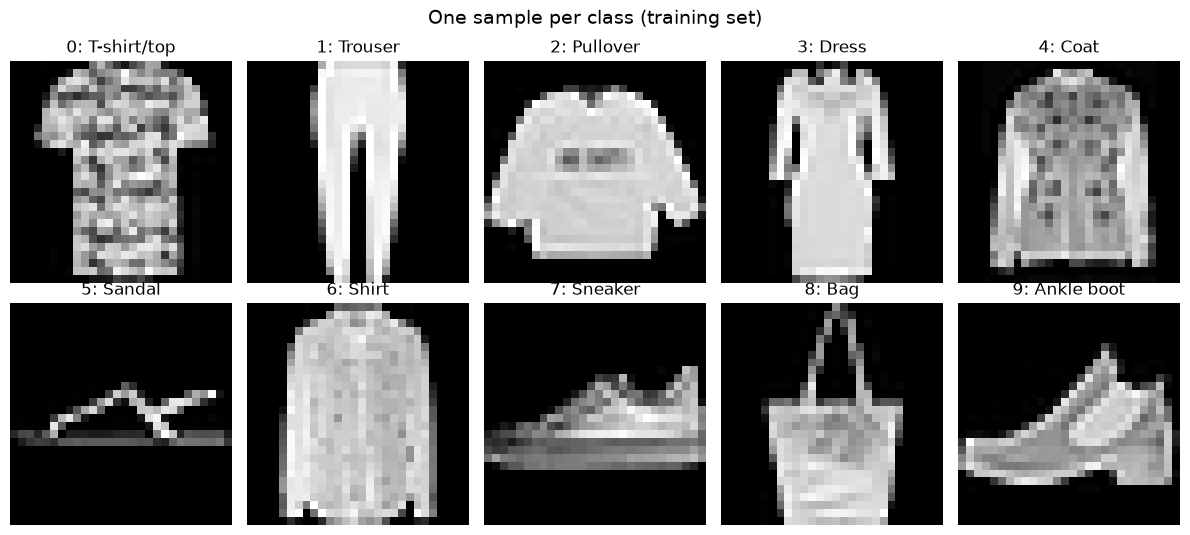

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.5))
for cls, ax in enumerate(axes.flat):
    idx = np.where(y_train_full == cls)[0][0]           # first image of this class
    ax.imshow(X_train_full[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"{cls}: {CLASS_NAMES[cls]}")
    ax.axis("off")
fig.suptitle("One sample per class (training set)", fontsize=14)
plt.tight_layout()
plt.show()

### 1.3 Class balance check
We count the images per class in both the training and test sets. A balanced dataset lets us use plain accuracy as a fair overall metric.


,class,train count,test count
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


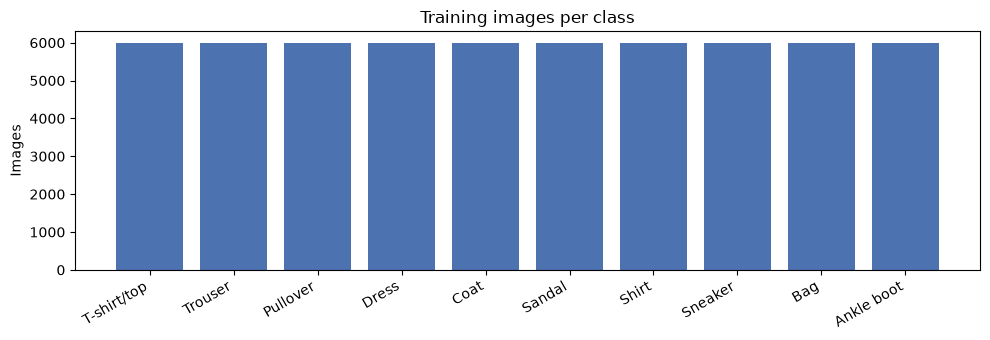

Perfectly balanced: True


In [5]:
balance = pd.DataFrame({
    "class": CLASS_NAMES,
    "train count": np.bincount(y_train_full, minlength=10),
    "test count": np.bincount(y_test, minlength=10),
})
display(balance)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(CLASS_NAMES, balance["train count"], color="#4C72B0")
ax.set_ylabel("Images")
ax.set_title("Training images per class")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

is_balanced = balance["train count"].nunique() == 1 and balance["test count"].nunique() == 1
print("Perfectly balanced:", is_balanced)

Every class has exactly **6,000 training** and **1,000 test** images so the dataset is perfectly balanced. That means plain accuracy is a fair headline metric and we don't need class weighting or resampling.

### 1.4 Scaling and flattening with the validation split

* **Scaling** means dividing by 255 so every pixel lies in [0, 1].
* **Flattening** is straightforward because the CSV already stores each image as a row of 784 values so each sample is already a 784-feature vector. (Images would otherwise be reshaped from 28 × 28 to 784.)
* **Validation split** means holding out 10,000 of the 60,000 training images (stratified so each class still has an equal share). The test set stays untouched until Task 3.

In [6]:
# Scale to [0, 1]
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Flatten (no-op for CSV data, shown explicitly for clarity)
X_train_full = X_train_full.reshape(len(X_train_full), -1)
X_test = X_test.reshape(len(X_test), -1)

# Stratified train / validation split
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=10_000,
    stratify=y_train_full, random_state=SEED)

print(f"Pixel range after scaling: {X_train.min():.1f} to {X_train.max():.1f}\n")
print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_val:   {X_val.shape}   y_val:   {y_val.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")

Pixel range after scaling: 0.0 to 1.0

X_train: (50000, 784)   y_train: (50000,)
X_val:   (10000, 784)   y_val:   (10000,)
X_test:  (10000, 784)   y_test:  (10000,)


**Final shapes are** training `(50000, 784)`, validation `(10000, 784)` and test `(10000, 784)`.

**Why scale pixels?** Scaling inputs to a small consistent range (0 to 1 instead of 0 to 255) keeps the weighted sums and gradients at a reasonable size so gradient descent converges faster and more stably instead of being dominated by large raw values.

---
## Task 2 Build and Train a Neural Network

### 2.1 Architecture with 784 → 128 → 10

| Layer | Size | Activation |
|---|---|---|
| Input | 784 | None |
| Hidden (fully connected) | 128 | ReLU |
| Output (fully connected) | 10 | Softmax |

**Note on softmax in PyTorch.** `nn.CrossEntropyLoss` applies log-softmax internally so the network outputs raw scores (logits) during training. This is numerically more stable than an explicit softmax layer followed by a log. When we need class probabilities (for example the prediction confidences in Task 3) we apply `torch.softmax` to the outputs. Mathematically the output layer is still a softmax layer.

In [7]:
def build_model():
    return nn.Sequential(
        nn.Linear(784, 128),
        nn.ReLU(),
        nn.Linear(128, 10),   # logits; softmax is applied inside the loss / at prediction time
    )

model = build_model()
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=10, bias=True)
)
Trainable parameters: 101770


### 2.2 Training setup

* Optimizer is **Adam** with learning rate 1e-3
* Loss is cross-entropy (softmax + negative log-likelihood)
* Batch size is 64
* Number of epochs is **40**

After every epoch the model is evaluated in inference mode on both the full training set and the validation set so the two curves are measured the same way.

In [8]:
BATCH_SIZE = 64
EPOCHS = 40
LR = 1e-3

to_tensors = lambda X, y: (torch.tensor(X), torch.tensor(y, dtype=torch.long))
Xtr_t, ytr_t = to_tensors(X_train, y_train)
Xva_t, yva_t = to_tensors(X_val, y_val)
Xte_t, yte_t = to_tensors(X_test, y_test)

loss_fn = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    logits = model(X)
    return loss_fn(logits, y).item(), (logits.argmax(1) == y).float().mean().item()

def train(model, epochs, seed=SEED, verbose=True):
    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=BATCH_SIZE, shuffle=True)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        model.train()
        for xb, yb in loader:
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()
        tl, ta = evaluate(model, Xtr_t, ytr_t)
        vl, va = evaluate(model, Xva_t, yva_t)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if verbose:
            print(f"Epoch {epoch:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} "
                  f"| val loss {vl:.4f} acc {va:.4f}")
    return hist

torch.manual_seed(SEED)
model = build_model()
t0 = time.time()
history = train(model, EPOCHS)
print(f"\nTraining time: {time.time() - t0:.1f} s")

Epoch  1/40 | train loss 0.4473 acc 0.8387 | val loss 0.4590 acc 0.8351


Epoch  2/40 | train loss 0.4227 acc 0.8467 | val loss 0.4462 acc 0.8379


Epoch  3/40 | train loss 0.3481 acc 0.8764 | val loss 0.3763 acc 0.8659


Epoch  4/40 | train loss 0.3279 acc 0.8824 | val loss 0.3612 acc 0.8697


Epoch  5/40 | train loss 0.3185 acc 0.8865 | val loss 0.3676 acc 0.8680


Epoch  6/40 | train loss 0.3006 acc 0.8919 | val loss 0.3550 acc 0.8719


... (30 outputs left out)

Epoch 37/40 | train loss 0.1152 acc 0.9588 | val loss 0.3790 acc 0.8876


Epoch 38/40 | train loss 0.1243 acc 0.9542 | val loss 0.3922 acc 0.8814


Epoch 39/40 | train loss 0.1181 acc 0.9568 | val loss 0.3851 acc 0.8920


Epoch 40/40 | train loss 0.1116 acc 0.9604 | val loss 0.3835 acc 0.8922

Training time: 67.4 s


### 2.3 Learning curves
We plot the per-epoch training and validation loss and accuracy. Comparing the two curves shows whether the model is still improving or starting to overfit.


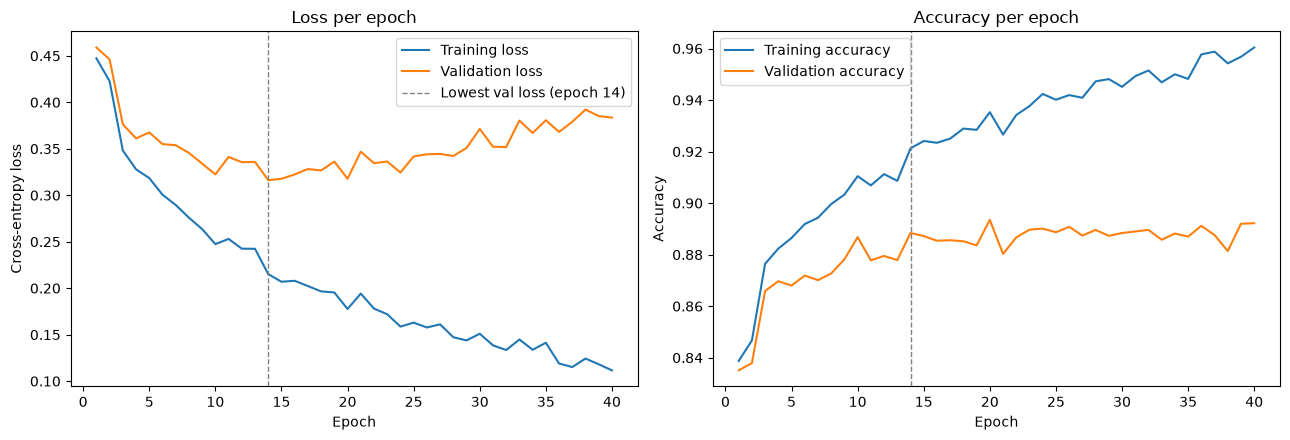

Lowest validation loss at epoch 14: 0.3162


,train acc,val acc,acc gap,train loss,val loss,loss gap
epoch,,,,,,
1,0.8387,0.8351,0.0036,0.4473,0.4590,0.0116
5,0.8865,0.8680,0.0185,0.3185,0.3676,0.0491
10,0.9105,0.8868,0.0237,0.2474,0.3224,0.0750
14,0.9213,0.8884,0.0329,0.2151,0.3162,0.1010
20,0.9353,0.8935,0.0418,0.1776,0.3178,0.1401
30,0.9451,0.8884,0.0567,0.1510,0.3714,0.2204
40,0.9604,0.8922,0.0682,0.1116,0.3835,0.2719


In [9]:
epochs_axis = np.arange(1, EPOCHS + 1)
best_epoch = int(np.argmin(history["val_loss"])) + 1

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(epochs_axis, history["train_loss"], label="Training loss")
ax1.plot(epochs_axis, history["val_loss"], label="Validation loss")
ax1.axvline(best_epoch, ls="--", c="gray", lw=1, label=f"Lowest val loss (epoch {best_epoch})")
ax1.set(title="Loss per epoch", xlabel="Epoch", ylabel="Cross-entropy loss")
ax1.legend()

ax2.plot(epochs_axis, history["train_acc"], label="Training accuracy")
ax2.plot(epochs_axis, history["val_acc"], label="Validation accuracy")
ax2.axvline(best_epoch, ls="--", c="gray", lw=1)
ax2.set(title="Accuracy per epoch", xlabel="Epoch", ylabel="Accuracy")
ax2.legend()
plt.tight_layout()
plt.show()

gap = pd.DataFrame({
    "epoch": epochs_axis,
    "train acc": history["train_acc"], "val acc": history["val_acc"],
    "acc gap": np.array(history["train_acc"]) - np.array(history["val_acc"]),
    "train loss": history["train_loss"], "val loss": history["val_loss"],
    "loss gap": np.array(history["val_loss"]) - np.array(history["train_loss"]),
}).set_index("epoch")
print(f"Lowest validation loss at epoch {best_epoch}: {min(history['val_loss']):.4f}")
gap.iloc[[0, 4, 9, best_epoch - 1, 19, 29, 39]].drop_duplicates().round(4)

### 2.4 How the gap between training and validation evolves

In the first few epochs the training and validation performance are almost identical. At epoch 1 they differ by only about 0.4 percentage points of accuracy which shows the model is still learning general patterns. As training continues, training loss keeps falling but validation loss bottoms out around **epoch 14 (≈ 0.316)** and then creeps back up to ≈ 0.38 by epoch 40. Meanwhile validation accuracy plateaus at about 88.5 to 89% while training accuracy climbs to about 96%. The accuracy gap therefore widens steadily from about 2 points at epoch 10 to about 4 at epoch 20 and about 7 at epoch 40. This is classic **overfitting**. After roughly 15 epochs the network is memorising the training images rather than learning features that generalise.